# TP2 — Diseño de filtros FIR por ventaneo de Kaiser

Bases teóricas, implementación parametrizable y verificación de la
respuesta en frecuencia de los 4 filtros del TP2 (pasa bajos, pasa altos,
pasa banda, elimina banda) en las 5 frecuencias de muestreo (8/16/22/44/48
kS/s).

Todo el diseño (fórmulas, búsqueda del orden del filtro y exportación a
`filter_coeffs.h`) vive en `disenio_filtros_tp2.py`, en esta misma carpeta
— acá lo importamos y lo ejercitamos, no se reimplementa nada.

**Especificación de los filtros (consigna del TP2):**

| Filtro | Corte(s) | Astop |
|---|---|---|
| Pasa bajos | Fc = 3600 Hz | 30 dB |
| Pasa altos | Fc = 35 Hz | 30 dB |
| Pasa banda | Fc1 = 35 Hz, Fc2 = 3500 Hz | 30 dB |
| Elimina banda | Fr = 50 Hz, Bw = 15 Hz | 25 dB |

El ancho de la banda de transición (`df`) **no** lo fija la consigna — es
una decisión de diseño; los valores usados en `main()` del script son un
punto de partida razonable, parametrizable.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('.'))
import numpy as np
import matplotlib.pyplot as plt

import disenio_filtros_tp2 as fir
print('Módulo cargado desde:', fir.__file__)

Módulo cargado desde: /home/wanda/Documentos/Facultad/DSP/DSP---TPs/TP2/filtros/disenio_filtros_tp2.py


## 1. Por qué no se puede diseñar el filtro ideal

Un filtro "pared" (ganancia 1 en la banda de paso, 0 en la de rechazo,
salto instantáneo) tiene como respuesta al impulso un **sinc**:

$$h_{ideal}[n] = \frac{\sin(\omega_c n)}{\pi n}$$

que se extiende de $-\infty$ a $+\infty$. Ningún filtro real puede tener
infinitos coeficientes, así que hay que truncarlo — pero truncarlo de golpe
(ventana rectangular) produce el **fenómeno de Gibbs**: un rebote en la
banda de rechazo que no baja de ~21 dB de atenuación sin importar cuántos
taps se usen.

## 2. Ventaneo: el trade-off ancho de transición vs. atenuación

En vez de cortar de golpe, se multiplica el sinc por una ventana que decae
suavemente hacia los bordes. Eso cambia el rebote fijo de Gibbs por un
trade-off continuo: **a mayor atenuación pedida en la banda de rechazo, más
ancha queda la banda de transición** (para una longitud de filtro fija), o
equivalentemente, para una transición fija, hace falta más longitud para
lograr más atenuación.

Las ventanas clásicas (Hamming, Blackman, ...) tienen una atenuación
**tope fija**, sin importar la longitud. La ventana de **Kaiser** agrega un
parámetro continuo, $\beta$, que permite pedir *cualquier* atenuación:

$$w[n] = \frac{I_0\left(\beta \sqrt{1 - \left(\frac{2n}{N-1}\right)^2}\right)}{I_0(\beta)}$$

## 3. Las dos fórmulas empíricas de Kaiser

Kaiser ajustó dos curvas empíricas (no derivadas analíticamente) que son el
corazón de `disenar_fir_kaiser`:

**Beta en función de la atenuación pedida** (depende *solo* de `Astop`, no
de `N` ni del ancho de transición):

$$
\beta = \begin{cases}
0 & A \le 21 \\
0.5842(A-21)^{0.4} + 0.07886(A-21) & 21 < A \le 50 \\
0.1102(A - 8.7) & A > 50
\end{cases}
$$

**Cantidad de taps en función de `Astop` y el ancho de transición
normalizado** ($\Delta f / F_s$):

$$N \approx \frac{A - 7.95}{2.285 \cdot 2\pi \cdot (\Delta f / F_s)} + 1$$

Esta fórmula es la que implementa internamente `disenar_fir_kaiser` para
calcular `numtaps` automáticamente cuando no se lo fuerza a mano.

In [2]:
# scipy.signal.kaiser_beta implementa exactamente la fórmula de beta(A)
print('beta(21) =', fir.kaiser_beta(21), '  (debe ser 0)')
print('beta(30) =', fir.kaiser_beta(30))
print('beta(60) =', fir.kaiser_beta(60))

beta(21) = 0.0   (debe ser 0)
beta(30) = 2.1166248611409806
beta(60) = 5.65326


## 4. El bloque parametrizable: `disenar_fir_kaiser`

Parametrizable en tipo, corte(s), Astop, Fs, ancho de transición y cantidad
de taps. Probamos primero el pasa bajos de la consigna, a 8 kS/s, dejando
que calcule `numtaps` automáticamente para cumplir Astop:

In [3]:
# Parámetros del filtro de prueba (Pasa Bajos)
fc_lp = 3600       # Frecuencia de corte (-6 dB) en Hz (especificada por consigna)
astop_lp = 30      # Atenuación mínima requerida en la banda de rechazo en dB (consigna)
fs_test = 8000     # Frecuencia de muestreo de prueba en Hz
df_lp = 400        # Ancho de la banda de transición en Hz (decisión de diseño)

r = fir.disenar_fir_kaiser('lowpass', cutoff=fc_lp, astop_db=astop_lp, fs=fs_test, df=df_lp)
print(f"numtaps={r['numtaps']}  beta={r['beta']:.3f}  "
      f"Astop float={r['astop_f']:.1f} dB  Astop Q15={r['astop_q']:.1f} dB  "
      f"ripple={r['ripple_q']:.2f} dB")


numtaps=34  beta=2.117  Astop float=31.6 dB  Astop Q15=31.6 dB  ripple=0.46 dB


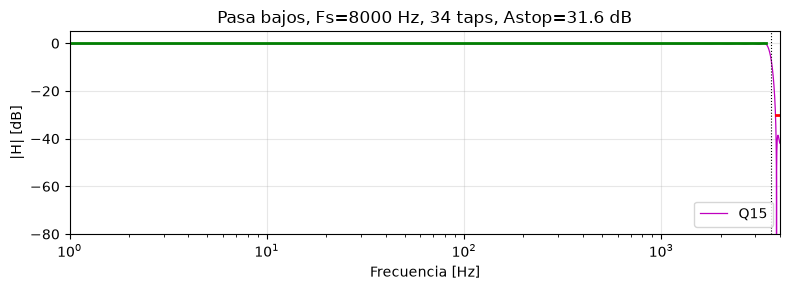

In [4]:
def graficar_uno(r, astop, titulo):
    f, H = fir._respuesta_db(r['q'] / 32768.0, r['fs'], fir.NFFT_DEFAULT)
    zonas, es_paso = fir.zonas_paso_rechazo(r['fs'], r['cutoff'], r['df'], r['pass_zero'])
    plt.figure(figsize=(8, 3))
    plt.semilogx(f[1:], H[1:], 'm', linewidth=0.9, label='Q15')
    for (lo, hi), paso in zip(zonas, es_paso):
        plt.plot([max(lo, 1), hi], [0, 0] if paso else [-astop]*2,
                 'g' if paso else 'r', linewidth=2)
    for c in r['cutoff']:
        plt.axvline(c, color='k', linestyle=':', linewidth=0.8)
    plt.xlim(1, r['fs']/2); plt.ylim(-80, 5); plt.grid(alpha=0.3)
    plt.ylabel('|H| [dB]'); plt.xlabel('Frecuencia [Hz]')
    plt.title(titulo); plt.legend(loc='lower right'); plt.tight_layout(); plt.show()

graficar_uno(r, 30, f"Pasa bajos, Fs=8000 Hz, {r['numtaps']} taps, Astop={r['astop_q']:.1f} dB")

## 5. `numtaps` también se puede fijar a mano

Si en vez de dejar que lo calcule se fuerza `numtaps`, la atenuación
lograda queda como dato de salida (puede no alcanzar la pedida si el
filtro es corto):

In [5]:
# Prueba fijando la cantidad de taps a mano para el pasa bajos a 8 kHz
df_test = 400  # Ancho de transición de referencia en Hz
for n in [11, 21, 33]:
    r = fir.disenar_fir_kaiser('lowpass', cutoff=fc_lp, astop_db=astop_lp, fs=fs_test, df=df_test, numtaps=n)
    print(f"numtaps={r['numtaps']:>3d}  Astop lograda={r['astop_q']:>5.1f} dB "
          f"({'cumple' if r['astop_q'] >= 30 else 'no cumple'} los 30 dB pedidos)")


numtaps= 12  Astop lograda=  9.9 dB (no cumple los 30 dB pedidos)
numtaps= 22  Astop lograda= 17.7 dB (no cumple los 30 dB pedidos)
numtaps= 34  Astop lograda= 31.6 dB (cumple los 30 dB pedidos)


## 6. Generaliza a los 4 tipos, incluyendo elimina banda por Fr/Bw

`firwin` acepta `pass_zero` como string (`'lowpass'`, `'highpass'`,
`'bandpass'`, `'bandstop'`), así que el mismo `disenar_fir_kaiser` cubre los
4 filtros sin ramas especiales. Para elimina banda, la consigna da
frecuencia de rechazo (`Fr`) y ancho de banda (`Bw`) en vez de los dos
cortes directamente — `cutoff_bandstop_fr_bw` hace la conversión:

In [6]:
# Parámetros de diseño para los 4 filtros a 8 kHz
df_lp = 400         # Ancho de transición para pasa bajos en Hz
df_hp = 60          # Ancho de transición para pasa altos en Hz (rechazo <= 5 Hz, paso >= 65 Hz)
df_bp = [60, 400]   # Anchos de transición inferior (60 Hz) y superior (400 Hz) para pasa banda

# Para elimina banda: frecuencia de notch y ancho de la banda a rechazar
fr_bs = 50          # Frecuencia central de rechazo en Hz (consigna)
bw_bs = 15          # Ancho de banda de rechazo en Hz (consigna: 42.5 a 57.5 Hz)
# Transición asimétrica: df_lo=35 Hz hacia continua y df_hi=90 Hz hacia altas frecuencias
df_bs = [35, 90]

cutoff_bs = fir.cutoff_bandstop_fr_bw(fr=fr_bs, bw=bw_bs, df=df_bs)
print(f'Elimina banda: Fr={fr_bs} Hz, Bw={bw_bs} Hz, df={df_bs} Hz  ->  cortes -6dB =', cutoff_bs)

casos = [
    ('lowpass',  3600,          30, df_lp),
    ('highpass', 35,            30, df_hp),
    ('bandpass', [35, 3500],    30, df_bp),
    ('bandstop', cutoff_bs,     25, df_bs),
]
for ftype, cutoff, astop, df in casos:
    r = fir.disenar_fir_kaiser(ftype, cutoff, astop, 8000, df)
    print(f"{ftype:<10s} numtaps={r['numtaps']:>5d}  Astop Q15={r['astop_q']:>5.1f} dB  "
          f"ripple={r['ripple_q']:.2f} dB")


Elimina banda: Fr=50 Hz, Bw=15 Hz, df=20 Hz  ->  cortes -6dB = [32.5 67.5]
lowpass    numtaps=   34  Astop Q15= 31.6 dB  ripple=0.46 dB
highpass   numtaps=  344  Astop Q15= 30.0 dB  ripple=0.58 dB
bandpass   numtaps=  346  Astop Q15= 30.7 dB  ripple=0.57 dB
bandstop   numtaps=  646  Astop Q15= 25.2 dB  ripple=1.20 dB


## 7. Los 20 diseños recomendados (4 filtros × 5 Fs) y su respuesta en frecuencia

Igual que `main()` en `disenio_filtros_tp2.py`: se calcula `numtaps`
automáticamente para cada filtro en cada una de las 5 frecuencias de
muestreo del TP, con los anchos de transición nominales.

In [7]:
# =============================================================================
# DEFINICIÓN DE PARÁMETROS CONFIGURABLES
# =============================================================================
# Frecuencias de muestreo soportadas por el sistema
fs_label = ['8k', '16k', '22k', '44k', '48k']
fs_list = [8000, 16000, 22000, 44000, 48000]

# --- 1. Pasa Bajos (LP) ---
# Consigna: Fc = 3600 Hz, Astop >= 30 dB
fc_lp = 3600          # Frecuencia de corte a -6 dB en Hz (consigna)
astop_lp = 30         # Atenuación mínima requerida en la banda de rechazo en dB (consigna)
df_lp = 400           # Ancho de la banda de transición en Hz (transición de 3400 a 3800 Hz)

# --- 2. Pasa Altos (HP) ---
# Consigna: Fc = 35 Hz, Astop >= 30 dB
fc_hp = 35            # Frecuencia de corte a -6 dB en Hz (consigna)
astop_hp = 30         # Atenuación mínima requerida en la banda de rechazo en dB (consigna)
df_hp = 60            # Ancho de la banda de transición en Hz (rechazo <= 5 Hz, paso >= 65 Hz)

# --- 3. Pasa Banda (BP) ---
# Consigna: Fc1 = 35 Hz, Fc2 = 3500 Hz, Astop >= 30 dB
fc_bp = [35, 3500]    # Frecuencias de corte inferior y superior a -6 dB en Hz (consigna)
astop_bp = 30         # Atenuación mínima requerida en la banda de rechazo en dB (consigna)
df_bp = [60, 400]     # Ancho de transición inferior (60 Hz) y superior (400 Hz)

# --- 4. Elimina Banda / Notch (BS) ---
# Consigna: Fr = 50 Hz, BW = 15 Hz, Astop >= 25 dB (rechazo [42.5, 57.5] Hz)
fr_bs = 50            # Frecuencia central de rechazo en Hz (consigna)
bw_bs = 15            # Ancho de banda de rechazo en Hz (consigna: 42.5 a 57.5 Hz)
astop_bs = 25         # Atenuación mínima requerida en la banda de rechazo en dB (consigna)
# Transición asimétrica: df_lo=35 Hz hacia continua (paso [0, 7.5] Hz) y
# df_hi=90 Hz hacia altas frecuencias para reducir fuertemente la cantidad de taps
df_bs = [35, 90]

# Cálculo de los cortes a -6 dB para el elimina banda a partir de Fr, BW y df
cutoff_bs = fir.cutoff_bandstop_fr_bw(fr=fr_bs, bw=bw_bs, df=df_bs)

# Lista de filtros con sus parámetros asignados mediante variables
filtros = [
    dict(key='lp', desc='Pasa bajos',    ftype='lowpass',
         cutoff=fc_lp,                              df=df_lp,      astop=astop_lp),
    dict(key='hp', desc='Pasa altos',    ftype='highpass',
         cutoff=fc_hp,                              df=df_hp,      astop=astop_hp),
    dict(key='bp', desc='Pasa banda',    ftype='bandpass',
         cutoff=fc_bp,                              df=df_bp,      astop=astop_bp),
    dict(key='bs', desc='Elimina banda', ftype='bandstop',
         cutoff=cutoff_bs,                          df=df_bs,      astop=astop_bs),
]

resultados = {}
print(f"{'filt':<4s} {'Fs':>6s} {'taps':>6s} {'beta':>7s} {'Astop req/real':>16s} {'ripple':>9s}")
for F in filtros:
    for fsl, fs in zip(fs_label, fs_list):
        r = fir.disenar_fir_kaiser(F['ftype'], F['cutoff'], F['astop'], fs, F['df'])
        resultados[(F['key'], fsl)] = r
        print(f"{F['key']:<4s} {fsl:>6s} {r['numtaps']:>6d} {r['beta']:>7.3f} "
              f"{F['astop']:>7.0f} / {r['astop_q']:<6.1f} {r['ripple_q']:>8.2f}dB")


filt     Fs   taps    beta   Astop req/real    ripple
lp       8k     34   2.117      30 / 31.6       0.46dB
lp      16k     64   2.117      30 / 30.5       0.53dB
lp      22k     86   2.117      30 / 30.1       0.53dB
lp      44k    170   2.117      30 / 30.2       0.54dB
lp      48k    186   2.117      30 / 30.3       0.53dB
hp       8k    344   2.117      30 / 30.0       0.58dB
hp      16k    688   2.117      30 / 30.0       0.58dB
hp      22k    948   2.117      30 / 30.2       0.57dB
hp      44k   1890   2.117      30 / 30.0       0.57dB
hp      48k   2052   2.117      30 / 30.0       0.60dB
bp       8k    346   2.117      30 / 30.7       0.57dB
bp      16k    690   2.117      30 / 30.2       0.57dB
bp      22k    946   2.117      30 / 30.2       0.58dB
bp      44k   1890   2.117      30 / 30.1       0.58dB
bp      48k   2064   2.117      30 / 30.0       0.58dB
bs       8k    646   1.333      25 / 25.2       1.20dB
bs      16k   1288   1.333      25 / 25.0       1.20dB
bs      22k

Los taps crecen con `Fs` (consistente con la fórmula de Kaiser: a
`df` fijo en Hz, `N ~ Fs/df`) — más notorio en pasaaltos/pasabanda/elimina
banda, cuyo corte más bajo está cerca de continua. Eso tiene impacto en el
costo de cómputo en la placa, pero **ese análisis queda fuera de este
notebook** — acá el objetivo es solo el diseño y la verificación de la
respuesta en frecuencia de cada filtro.

Un gráfico por filtro, con las 5 frecuencias de muestreo superpuestas en
subplots. La línea verde marca la banda de paso exigida, la roja el piso de
`Astop`, y las punteadas verticales los cortes -6 dB. Magenta es la
respuesta real sobre los coeficientes **Q15** (los que se exportan a
`filter_coeffs.h`), no los coeficientes en punto flotante.

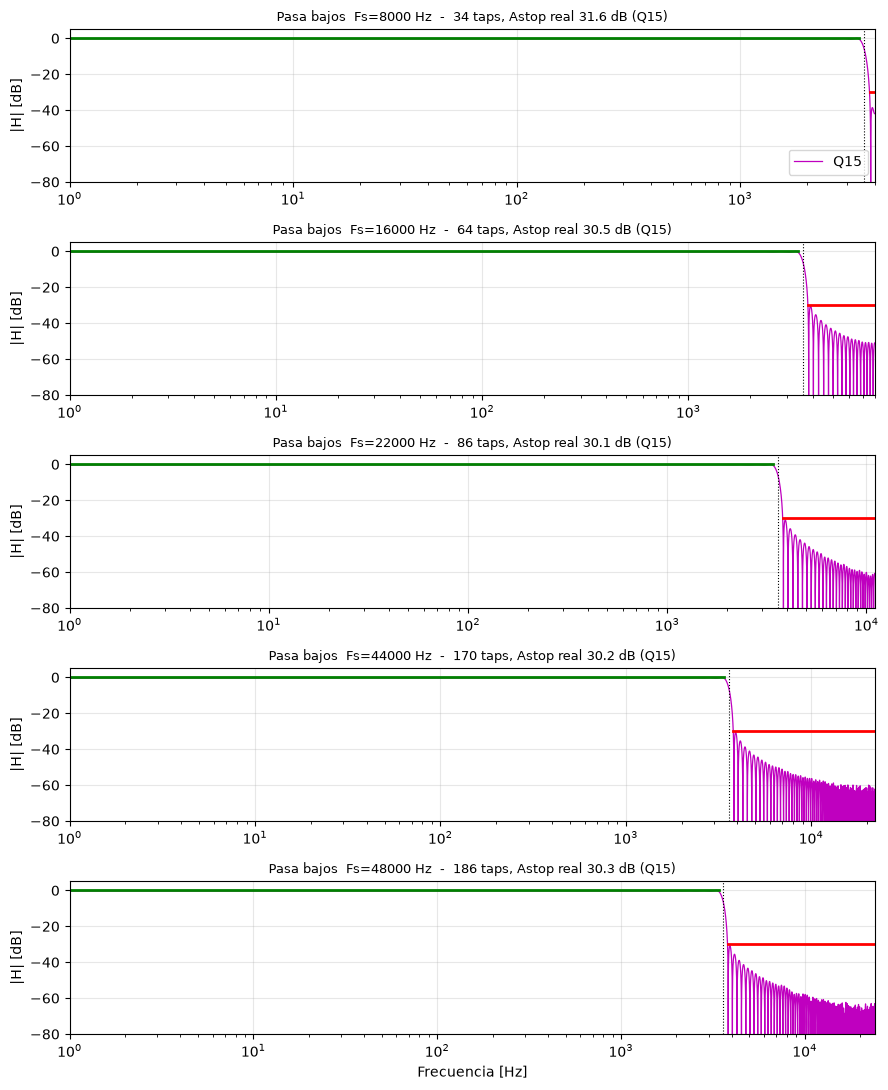

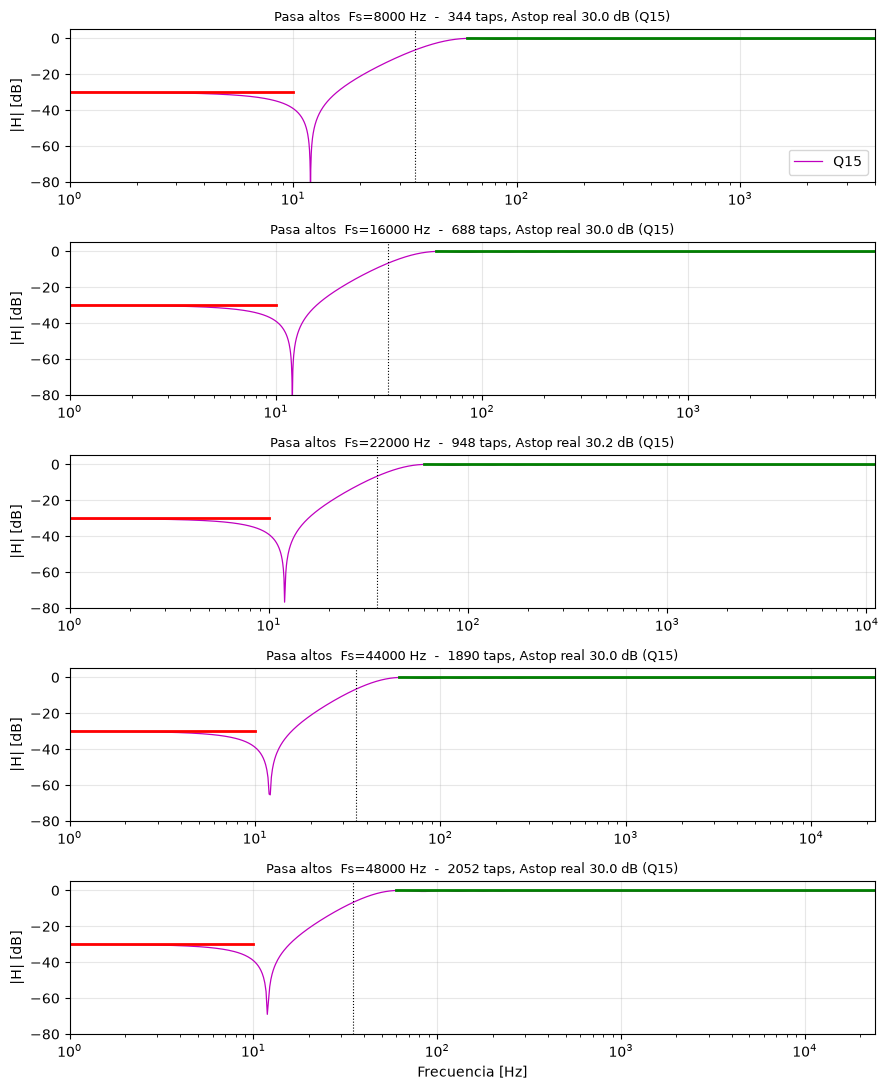

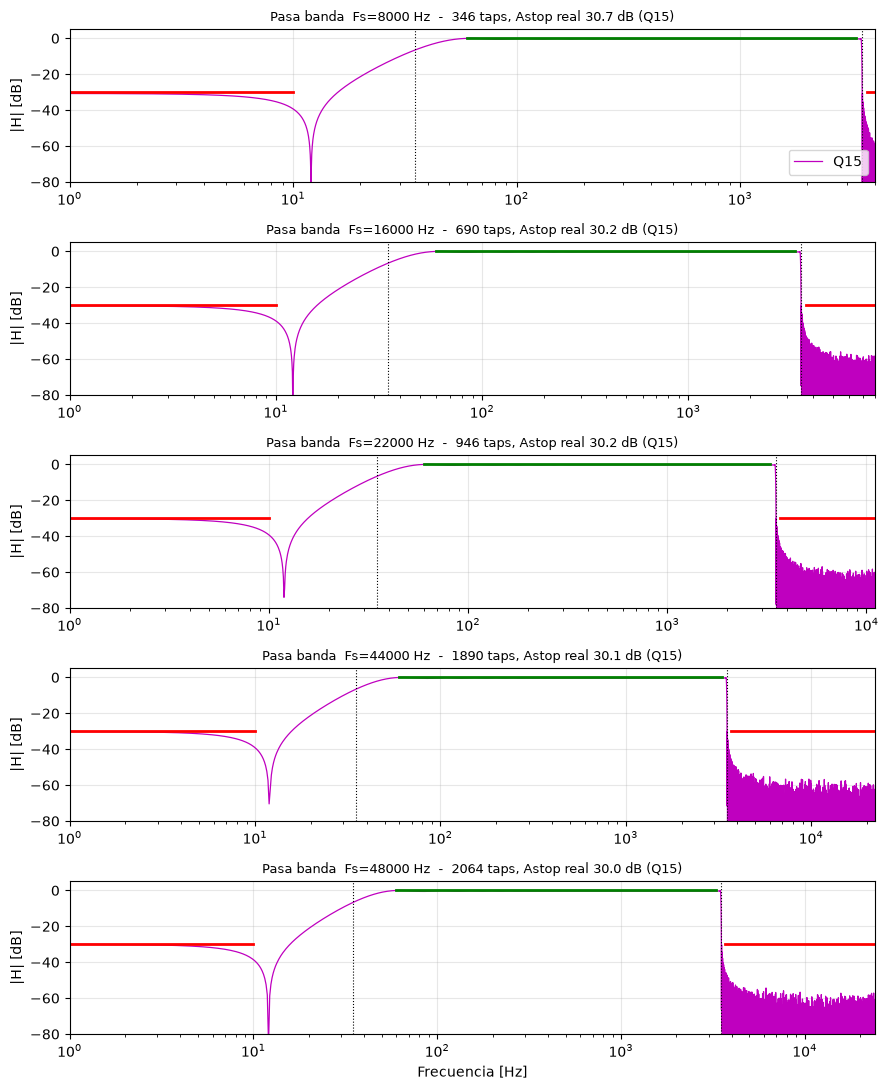

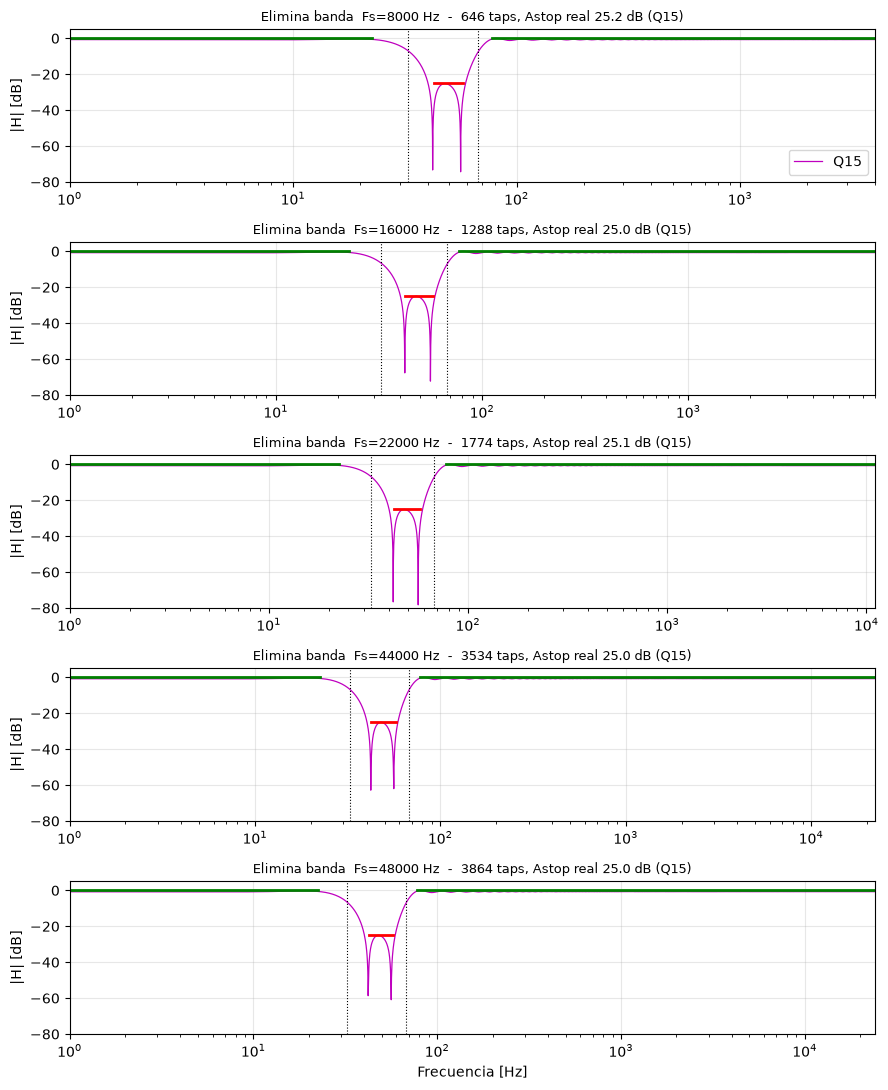

In [8]:
for F in filtros:
    n = len(fs_label)
    fig, axes = plt.subplots(n, 1, figsize=(9, 2.2 * n))
    for ax, fsl in zip(axes, fs_label):
        r = resultados[(F['key'], fsl)]
        fs = r['fs']
        f, Hq = fir._respuesta_db(r['q'] / 32768.0, fs, fir.NFFT_DEFAULT)
        ax.semilogx(f[1:], Hq[1:], 'm', linewidth=0.9, label='Q15')
        zonas, es_paso = fir.zonas_paso_rechazo(fs, r['cutoff'], r['df'], r['pass_zero'])
        for (lo, hi), paso in zip(zonas, es_paso):
            ax.plot([max(lo, 1), hi], [0, 0] if paso else [-F['astop']]*2,
                    'g' if paso else 'r', linewidth=2)
        for c in r['cutoff']:
            ax.axvline(c, color='k', linestyle=':', linewidth=0.8)
        ax.set_xlim(1, fs/2); ax.set_ylim(-80, 5); ax.grid(alpha=0.3)
        ax.set_ylabel('|H| [dB]')
        ax.set_title(f"{F['desc']}  Fs={fs} Hz  -  {r['numtaps']} taps, "
                     f"Astop real {r['astop_q']:.1f} dB (Q15)", fontsize=9)
    axes[0].legend(loc='lower right')
    axes[-1].set_xlabel('Frecuencia [Hz]')
    fig.tight_layout()
    plt.show()

## 8. Exportar `filter_coeffs.h`

Formato listo para `arm_fir_init_q15`/`arm_fir_q15` en `processing_stage.c`.

In [9]:
out_dir = os.path.abspath('.')
h_path = os.path.join(out_dir, '..', 'MCXN947_Project_TP2', 'source', 'filter_coeffs.h')
fir.exportar_header(resultados, filtros, fs_label, h_path)

Exportado: /home/wanda/Documentos/Facultad/DSP/DSP---TPs/TP2/filtros/../MCXN947_Project_TP2/source/filter_coeffs.h
MAX_FIR_TAPS = 3864; coeficientes totales = 23504 (45.9 KB en flash)


## Conclusiones

- La fórmula de Kaiser hace explícito que el costo de un FIR (`N`) depende
  de `Astop` y del ancho de transición *normalizado* `df/Fs`, no de `df` ni
  `Fs` por separado.
- `disenar_fir_kaiser` es el único bloque de diseño necesario para los 4
  filtros de la consigna: alcanza con cambiar `ftype`/`cutoff`/`df` (y, para
  elimina banda, convertir Fr/Bw con `cutoff_bandstop_fr_bw`).
- `numtaps` se puede calcular automáticamente o fijar a mano; si se fija,
  la atenuación lograda es un resultado a verificar, no una garantía.
- Los 20 diseños (4 filtros × 5 Fs) cumplen el `Astop` pedido sobre los
  coeficientes **Q15**, que son los que se exportan a `filter_coeffs.h`.